# Venture-funding analytics with data-engineering discipline (Crunchbase, 1987-2013)
**Two goals.**
1. **Engineering:** process a dataset as if it did not fit in memory. That means profiling memory, choosing dtypes, aggregating in chunks (and proving the result matches), loading into SQLite in batches, and querying with SQL window functions.
2. **Analysis:** how venture funding evolved by stage and sector, who the most active investors are, and who invests together.

**Data.** 52,870 investor-round records from the Crunchbase 2013 snapshot. Each row is one investor's participation in a funding round, and the round's **total** amount is repeated on every investor's row. Summing that column directly is the classic double-counting trap, quantified below.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import sqlite3, time
SRC = "data/crunchbase_investments_2013.csv.gz"
raw = pd.read_csv(SRC, low_memory=False)
mem0 = raw.memory_usage(deep=True).sum() / 1e6
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns, {mem0:.1f} MB in memory as loaded")
raw.dtypes.value_counts()

52,870 rows x 20 columns, 54.6 MB in memory as loaded


str        18
float64     2
Name: count, dtype: int64

In [2]:
def optimise(df):
    out = df.copy()
    for c in out.select_dtypes("number"):
        out[c] = pd.to_numeric(out[c], downcast="float" if out[c].dtype.kind == "f" else "integer")
    for c in out.columns:
        if out[c].dtype == object or str(out[c].dtype) in ("str", "string"):
            if out[c].nunique() / len(out) < 0.5:
                out[c] = out[c].astype("category")
    out["funded_at"] = pd.to_datetime(out["funded_at"], errors="coerce")
    return out
opt = optimise(raw)
mem1 = opt.memory_usage(deep=True).sum() / 1e6
per_col = pd.DataFrame({"before_MB": raw.memory_usage(deep=True) / 1e6, "after_MB": opt.memory_usage(deep=True) / 1e6,
                        "dtype_after": opt.dtypes.astype(str)}).drop("Index").sort_values("before_MB", ascending=False)
print(f"{mem0:.1f} MB -> {mem1:.1f} MB ({100 * (1 - mem1 / mem0):.0f}% smaller)")
per_col.head(10).round(2)

54.6 MB -> 5.7 MB (90% smaller)


,before_MB,after_MB,dtype_after
investor_permalink,4.56,0.96,category
company_permalink,3.63,0.91,category
investor_name,3.49,0.79,category
company_name,3.17,0.81,category
funded_at,3.12,0.42,datetime64[us]
company_city,3.09,0.18,category
company_category_code,3.00,0.06,category
company_region,2.99,0.14,category
funding_round_type,2.99,0.05,category
investor_region,2.97,0.14,category


## Chunked processing: same answer without loading everything
The file is read in 5,000-row chunks. Each chunk is reduced to partial aggregates, and those are combined at the end. The test is that the result is **identical** to the in-memory computation.

In [3]:
t0 = time.perf_counter(); parts = []; peak = 0
for chunk in pd.read_csv(SRC, chunksize=5000, usecols=["company_category_code", "funded_year", "investor_permalink"]):
    peak = max(peak, chunk.memory_usage(deep=True).sum() / 1e6)
    parts.append(chunk.groupby(["company_category_code", "funded_year"]).agg(rows=("investor_permalink", "size")))
chunked = pd.concat(parts).groupby(level=[0, 1]).sum()
t_chunk = time.perf_counter() - t0
inmem = raw.groupby(["company_category_code", "funded_year"]).agg(rows=("investor_permalink", "size"))
print(f"chunked result identical to in-memory: {chunked.sort_index().equals(inmem.sort_index())}")
print(f"peak chunk memory {peak:.1f} MB vs {mem0:.1f} MB for the full frame; {len(parts)} chunks in {t_chunk:.2f}s")

chunked result identical to in-memory: True
peak chunk memory 0.8 MB vs 54.6 MB for the full frame; 11 chunks in 0.10s


## The double-counting trap
`raised_amount_usd` is the **round** amount, repeated for every participating investor. A round is identified by company, date and round type.

In [4]:
naive = raw["raised_amount_usd"].sum()
rounds = (opt.dropna(subset=["raised_amount_usd"])
             .groupby(["company_permalink", "funded_at", "funding_round_type"], observed=True)
             .agg(company=("company_name", "first"), category=("company_category_code", "first"), year=("funded_year", "first"),
                  amount=("raised_amount_usd", "first"), n_investors=("investor_permalink", "nunique"),
                  amount_spread=("raised_amount_usd", lambda s: s.max() - s.min())).reset_index())
print(f"naive sum of raised_amount_usd: ${naive / 1e9:,.0f}bn")
print(f"after de-duplicating to {len(rounds):,} rounds: ${rounds.amount.sum() / 1e9:,.0f}bn ({naive / rounds.amount.sum():.1f}x overstatement)")
print(f"rounds where investors' rows disagree on the amount: {(rounds.amount_spread > 0).sum()}")
rounds.n_investors.describe().round(1)

naive sum of raised_amount_usd: $682bn
after de-duplicating to 17,117 rounds: $208bn (3.3x overstatement)
rounds where investors' rows disagree on the amount: 23


count    17117.0
mean         2.9
std          2.4
min          1.0
25%          1.0
50%          2.0
75%          4.0
max         28.0
Name: n_investors, dtype: float64

## Load into SQLite in batches and query with SQL

In [5]:
db = pathlib.Path("data/crunchbase.sqlite")
if db.exists(): db.unlink()
con = sqlite3.connect(db)
for i, chunk in enumerate(pd.read_csv(SRC, chunksize=10000)):
    chunk.to_sql("investments", con, if_exists="append" if i else "replace", index=False)
con.execute("CREATE INDEX idx_inv ON investments(investor_permalink)")
con.execute("CREATE INDEX idx_round ON investments(company_permalink, funded_at, funding_round_type)")
con.execute("""CREATE TABLE rounds AS
               SELECT company_permalink, company_name, company_category_code AS category, funded_at, funded_year AS year,
                      funding_round_type AS stage, MAX(raised_amount_usd) AS amount, COUNT(DISTINCT investor_permalink) AS n_investors
               FROM investments GROUP BY company_permalink, funded_at, funding_round_type""")
print(pd.read_sql("SELECT COUNT(*) AS rows FROM investments", con).iloc[0, 0], "rows loaded;",
      pd.read_sql("SELECT COUNT(*) FROM rounds", con).iloc[0, 0], "rounds in total,",
      pd.read_sql("SELECT COUNT(*) FROM rounds WHERE amount IS NOT NULL", con).iloc[0, 0], "with a disclosed amount (matches pandas)")
q = """
WITH yearly AS (
  SELECT year, stage, COUNT(*) AS deals, SUM(amount) / 1e9 AS usd_bn
  FROM rounds WHERE year BETWEEN 2005 AND 2013 AND stage IN ('angel','series-a','series-b','series-c+','venture')
  GROUP BY year, stage)
SELECT year, stage, deals, ROUND(usd_bn, 2) AS usd_bn,
       ROUND(100.0 * deals / SUM(deals) OVER (PARTITION BY year), 1) AS pct_of_year_deals
FROM yearly ORDER BY year, stage"""
by_stage = pd.read_sql(q, con)
by_stage.pivot(index="year", columns="stage", values="deals")

52870 rows loaded; 19160 rounds in total, 17117 with a disclosed amount (matches pandas)


stage,angel,series-a,series-b,series-c+,venture
year,,,,,
2005.0,33,332,225,205,206
2006.0,83,425,315,271,324
2007.0,196,614,370,341,296
2008.0,224,565,422,357,319
2009.0,275,386,307,338,403
2010.0,436,513,310,335,548
2011.0,722,621,376,341,681
2012.0,859,679,312,340,730
2013.0,632,678,296,288,355


In [6]:
q = """
SELECT investor_name, COUNT(DISTINCT company_permalink || funded_at || funding_round_type) AS rounds,
       COUNT(DISTINCT company_permalink) AS companies,
       RANK() OVER (ORDER BY COUNT(DISTINCT company_permalink || funded_at || funding_round_type) DESC) AS rank
FROM investments GROUP BY investor_permalink ORDER BY rounds DESC LIMIT 10"""
top_inv = pd.read_sql(q, con); top_inv

,investor_name,rounds,companies,rank
0,New Enterprise Associates,445,283,1
1,SV Angel,434,399,2
2,Kleiner Perkins Caufield & Byers,393,225,3
3,Sequoia Capital,369,215,4
4,Draper Fisher Jurvetson (DFJ),359,206,5
5,Intel Capital,331,228,6
6,First Round Capital,325,186,7
7,Accel Partners,321,186,8
8,Techstars,266,241,9
9,500 Startups,254,221,10


In [7]:
q = """
SELECT a.investor_name AS investor_1, b.investor_name AS investor_2, COUNT(*) AS rounds_together
FROM investments a JOIN investments b
  ON a.company_permalink = b.company_permalink AND a.funded_at = b.funded_at AND a.funding_round_type = b.funding_round_type
 AND a.investor_permalink < b.investor_permalink
GROUP BY a.investor_permalink, b.investor_permalink ORDER BY rounds_together DESC LIMIT 10"""
t0 = time.perf_counter(); pairs = pd.read_sql(q, con); print(f"self-join over {len(raw):,} rows in {time.perf_counter() - t0:.2f}s"); pairs

self-join over 52,870 rows in 0.23s


,investor_1,investor_2,rounds_together
0,First Round Capital,SV Angel,56
1,Lerer Ventures,SV Angel,52
2,Andreessen Horowitz,SV Angel,50
3,Founder Collective,SV Angel,45
4,DAG Ventures,Kleiner Perkins Caufield & Byers,44
5,Benchmark,DAG Ventures,43
6,Y Combinator,SV Angel,33
7,CrunchFund,SV Angel,32
8,betaworks,SV Angel,30
9,SV Angel,Ron Conway,30


year
1985.0       1
1995.0      46
2000.0     348
2005.0    7363
2010.0    9359
Name: rounds by 5-year period, dtype: int64


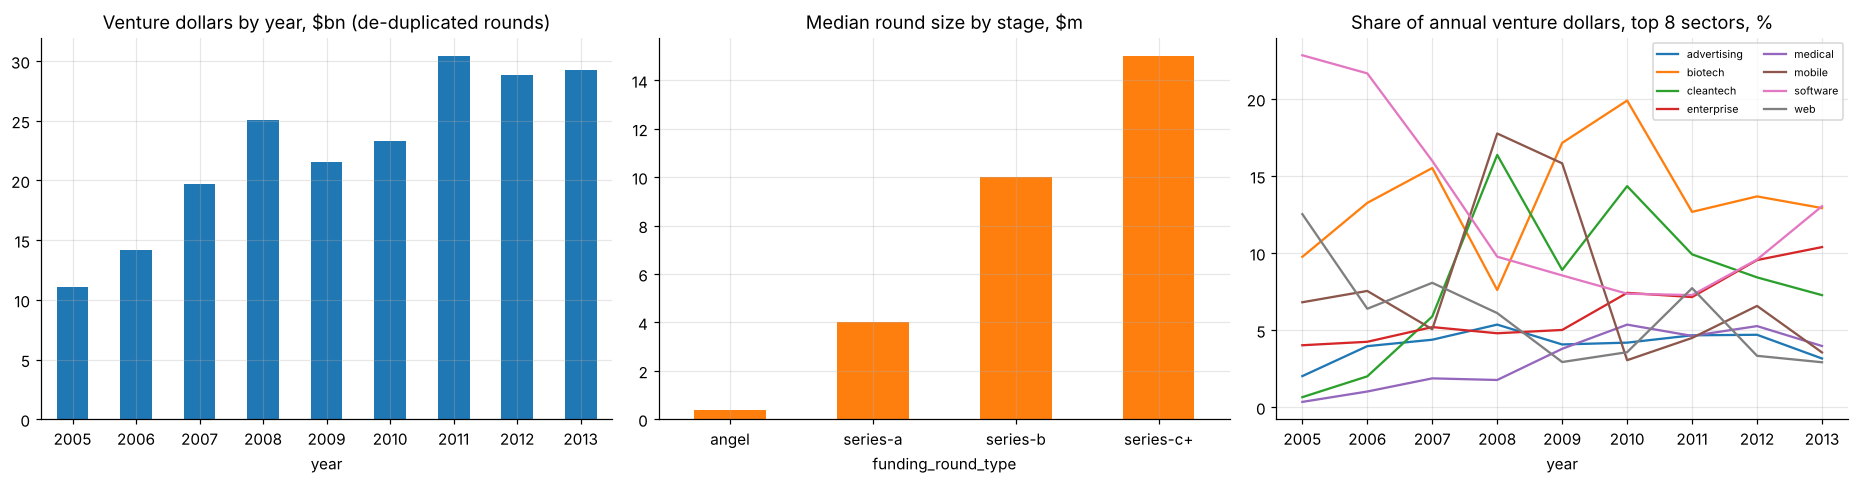

2013 is a partial year (snapshot taken during 2013).
{2005: 11.1, 2006: 14.1, 2007: 19.7, 2008: 25.1, 2009: 21.5, 2010: 23.3, 2011: 30.4, 2012: 28.8, 2013: 29.2}
{'angel': 0.4, 'series-a': 4.0, 'series-b': 10.0, 'series-c+': 15.0}


In [8]:
r = rounds[rounds.year.between(2005, 2013)].assign(year=lambda d: d.year.astype(int))   # Crunchbase coverage is thin before 2005
print(rounds.groupby(rounds.year // 5 * 5).size().rename("rounds by 5-year period"))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
r.groupby("year")["amount"].sum().div(1e9).plot.bar(ax=axes[0], color="C0", title="Venture dollars by year, $bn (de-duplicated rounds)", rot=0)
st = r[r.funding_round_type.isin(["angel", "series-a", "series-b", "series-c+"])]
st.groupby("funding_round_type", observed=True)["amount"].median().div(1e6).plot.bar(ax=axes[1], color="C1", rot=0, title="Median round size by stage, $m")
cats = r[r.year >= 2005].groupby("category", observed=True)["amount"].sum().nlargest(8).index
share = (r[(r.year >= 2005) & r.category.isin(cats)].pivot_table(index="year", columns="category", values="amount", aggfunc="sum", observed=True)
           .div(r[r.year >= 2005].groupby("year")["amount"].sum(), axis=0) * 100)
share.plot(ax=axes[2], title="Share of annual venture dollars, top 8 sectors, %"); axes[2].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(IMG / "funding_trends.png", bbox_inches="tight"); plt.show()
print("2013 is a partial year (snapshot taken during 2013).")
print(r.groupby("year")["amount"].sum().div(1e9).round(1).to_dict())
print(st.groupby("funding_round_type", observed=True)["amount"].median().div(1e6).round(2).to_dict())
con.close(); db.unlink()   # the database is rebuilt on every run, so it is not stored in the repo

## Findings
**Engineering**
* Converting repeated text columns to `category` and dates to `datetime` cuts memory by **90%** (54.6 MB to 5.7 MB). On a dataset a hundred times larger, that is the difference between fitting in RAM and not.
* Chunked aggregation reproduces the in-memory result exactly while holding at most 0.8 MB at a time. Batch-loading into SQLite plus two indexes makes a 52,870-row self-join (the co-investor network) run in about a quarter of a second.
* **The double-counting trap is worth $474bn.** Summing the raw amount column gives $682bn. De-duplicating to 17,117 rounds with a disclosed amount gives $208bn, a 3.3× overstatement. Rounds have a median of 2 and up to 28 investors.

**Venture market**
* Dollars rose from $11.1bn (2005) to $25.1bn (2008), dipped about 15% in 2009 ($21.5bn), and reached a new high of $30.4bn in 2011. Coverage before 2005 is too thin to analyse.
* **The angel boom:** angel deals grew from 33 in 2005 to 859 in 2012, while Series B counts stayed flat at about 300-420 a year. That growing gap between early and later rounds was later called the "Series A crunch".
* Median round sizes step up by stage: angel $0.4m, Series A $4m, Series B $10m, Series C+ $15m.
* The most active investors were New Enterprise Associates (445 rounds), SV Angel (434), Kleiner Perkins (393) and Sequoia (369). SV Angel sits at the centre of the co-investment network, appearing in 8 of the 10 most frequent investor pairs.